# Experiment No. 11 (Computer Laboratory – I BE AI&DS)

**Aim:** Data Aggregation  
**Problem Statement:** Analyzing Sales Performance by Region in a Retail Company  
**Dataset:** `"Retail_Sales_Data.csv"`  

**Tasks to Perform:**
1. Import the "Retail_Sales_Data.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Identify the relevant variables for aggregating sales data (Region, Sales_Amount, Product_Category).
4. Group the sales data by region and calculate the total sales amount for each region.
5. Create bar plots or pie charts to visualize the sales distribution by region.
6. Identify the top-performing regions based on the highest sales amount.
7. Group the sales data by region and product category to calculate the total sales amount for each combination.
8. Create stacked bar plots or grouped bar plots to compare the sales amounts across different regions and product categories.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Import dataset
df = pd.read_csv("Retail_Sales_Data.csv")

# Explore dataset
print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

# Relevant variables
print("\nVariables for Aggregation:")
print("Region, Product_Category, Sales_Amount, Quantity_Sold")

Dataset Shape: (200, 6)


,Transaction_ID,Date,Region,Product_Category,Quantity_Sold,Sales_Amount
0,TXN1001,2024-02-21,South,Electronics,1,1214
1,TXN1002,2024-01-15,South,Clothing,1,445
2,TXN1003,2024-03-12,South,Clothing,8,3609
3,TXN1004,2024-03-01,North,Home Appliances,2,1685
4,TXN1005,2024-01-21,East,Home Appliances,8,6802



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction_ID    200 non-null    str  
 1   Date              200 non-null    str  
 2   Region            200 non-null    str  
 3   Product_Category  200 non-null    str  
 4   Quantity_Sold     200 non-null    int64
 5   Sales_Amount      200 non-null    int64
dtypes: int64(2), str(4)
memory usage: 15.8 KB

Statistical Summary:


,Quantity_Sold,Sales_Amount
count,200.000000,200.00000
mean,4.885000,3007.31500
std,2.581686,2772.08935
min,1.000000,87.00000
25%,3.000000,879.25000
50%,5.000000,2184.50000
75%,7.000000,4240.50000
max,9.000000,10842.00000



Variables for Aggregation:
Region, Product_Category, Sales_Amount, Quantity_Sold


In [3]:
# Calculate total sales for each region
regional_sales = df.groupby('Region')['Sales_Amount'].sum()

# Sort regions by sales
regional_sales = regional_sales.sort_values(ascending=False)

print("Total Sales by Region:")
print(regional_sales)

# Identify top-performing region
print("\nTop Performing Region:", regional_sales.idxmax())
print("Highest Sales:", regional_sales.max())

Total Sales by Region:
Region
North      154974
East       140912
South      125215
West       101104
Central     79258
Name: Sales_Amount, dtype: int64

Top Performing Region: North
Highest Sales: 154974


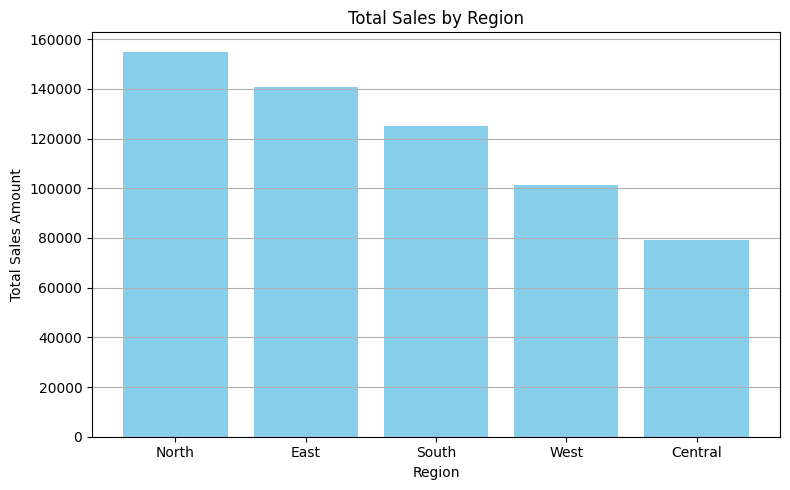

In [4]:
plt.figure(figsize=(8, 5))

plt.bar(regional_sales.index, regional_sales.values, color='skyblue')

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales Amount")
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [5]:
# Calculate total sales for each region and product category
region_category = df.groupby(
    ['Region', 'Product_Category']
)['Sales_Amount'].sum().unstack(fill_value=0)

print("Sales by Region and Product Category:")
display(region_category)

Sales by Region and Product Category:


Product_Category,Clothing,Electronics,Footwear,Groceries,Home Appliances
Region,,,,,
Central,12441,37231,7370,2697,19519
East,21536,61159,18889,2676,36652
North,13248,63468,10924,8694,58640
South,26536,67153,6037,6789,18700
West,18934,52663,9796,4409,15302


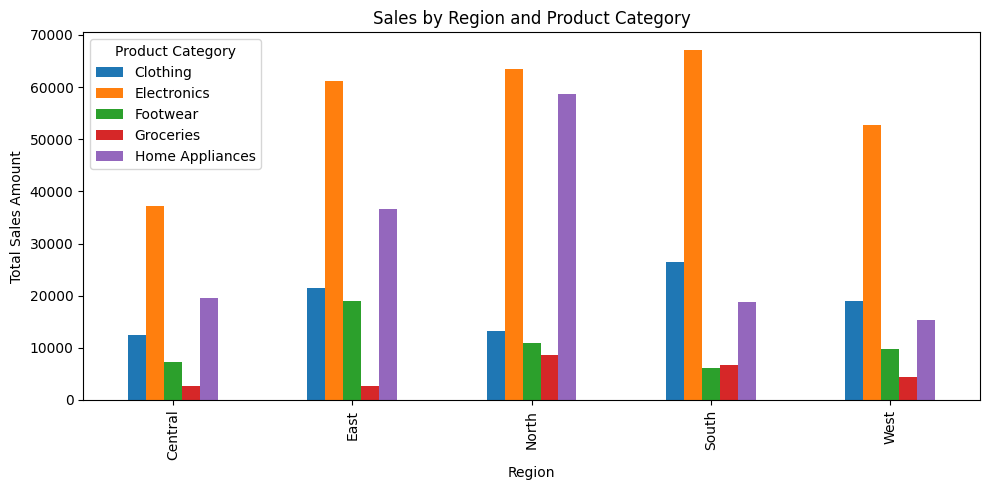

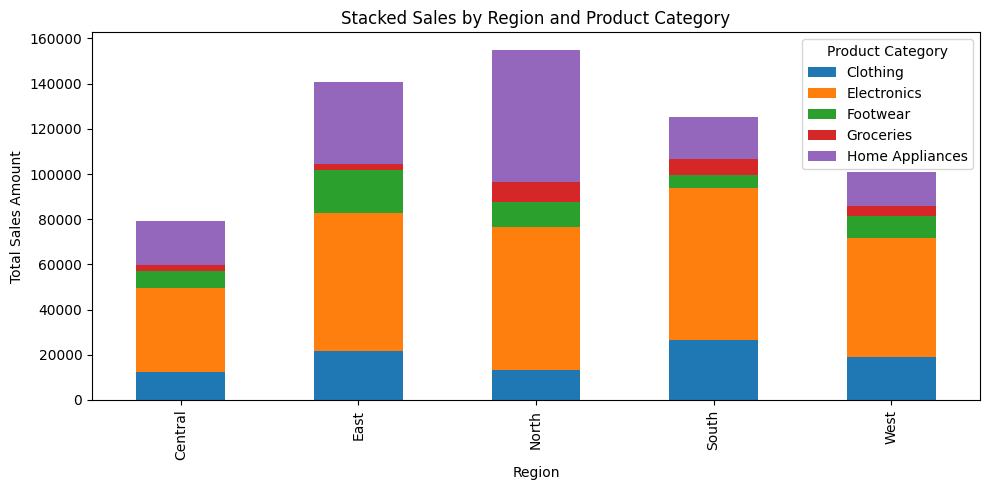

In [6]:
# Grouped bar plot
region_category.plot(kind='bar', figsize=(10, 5))

plt.title("Sales by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Total Sales Amount")
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()

# Stacked bar plot
region_category.plot(kind='bar', stacked=True, figsize=(10, 5))

plt.title("Stacked Sales by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Total Sales Amount")
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()